# Classificação de ocorrências de roubo e furto de celulares em São Paulo com MLP

**Global Solution – Aprendizado Profundo com Redes Neurais Convolucionais – FIAP, Ciência da Computação**

| Integrante | RM | E-mail |
|---|---|---|
| Gustavo Franzoti Gonçalves | RM566983 | RM566983@fiap.com.br |
| Maykon Santana Fonseca | RM567041 | RM567041@fiap.com.br |

O objetivo é treinar uma Multilayer Perceptron que, a partir das características de um boletim de ocorrência
de celular subtraído na capital paulista, diga se o registro é mais compatível com **roubo** (art. 157) ou com
**furto** (art. 155). A rede não estima a chance de um crime acontecer em um lugar ou horário; ela recebe uma
ocorrência já registrada (ou hipotética) e estima a qual das duas naturezas ela se parece mais.

Organização do notebook, seguindo as seções do enunciado:

1. Base de dados (seção 3 do enunciado)
2. Preparação dos dados (4.1)
3. Implementação da MLP (4.2)
4. Experimentos com arquiteturas (4.3)
5. Avaliação e seleção do modelo (4.4)
6. Exportação do modelo para a aplicação web (5)

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import config
from src.dados import carregar_bruto, filtrar_capital, preparar_base
from src.modelo import MLP, exportar_pesos, metricas, prever_proba, treinar
from src.preprocessamento import PreProcessador, dividir

pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
FIG = config.PASTA_FIGURAS
FIG.mkdir(parents=True, exist_ok=True)
print("PyTorch", torch.__version__)

PyTorch 2.12.0+cpu


## 1. Base de dados

**Fonte:** Secretaria da Segurança Pública do Estado de São Paulo (SSP-SP), Portal de Estatísticas – Consultas,
seção *Bases de Dados* → *Celulares subtraídos* → período **2025**
(<https://www.ssp.sp.gov.br/estatistica/consultas>). Arquivo `CelularesSubtraidos_2025.xlsx`, baixado em
17/11/2026. A planilha traz as abas `METODOLOGIA`, `DICIONARIO DE DADOS` e `CELULAR_2025`, esta última com
383.635 linhas e 55 colunas extraídas dos sistemas R.D.O. e S.P.J. da Polícia Civil.

Escolhemos essa base porque ela é a única das três bases de objetos subtraídos em que roubo e furto aparecem
com volume parecido, e porque o objeto é sempre o mesmo (telefone celular). Isso evita que a rede aprenda
a diferença entre "tipo de objeto" em vez da diferença entre os crimes.

O arquivo bruto tem 108 MB e não vai para o GitHub. O script `scripts/baixar_dados.py` faz o download e
a função `preparar_base()` gera o CSV de 20 mil boletins usado daqui em diante, que está versionado em
`data/processed/`. Se o arquivo bruto não estiver na máquina, as células de exploração da base bruta são
puladas e o notebook continua a partir do CSV.

In [2]:
TEM_BRUTO = config.ARQ_PARQUET.exists() or config.ARQ_BRUTO.exists()
if TEM_BRUTO:
    bruto = carregar_bruto()
    print(bruto.shape)
    print(list(bruto.columns))
else:
    print("Base bruta ausente: rode `python scripts/baixar_dados.py` para refazer esta parte.")

(383635, 55)
['ID_DELEGACIA', 'NOME_DEPARTAMENTO', 'NOME_SECCIONAL', 'NOME_DELEGACIA', 'NOME_MUNICIPIO', 'ANO_BO', 'NUM_BO', 'VERSAO', 'NOME_DEPARTAMENTO_CIRC', 'NOME_SECCIONAL_CIRC', 'NOME_DELEGACIA_CIRC', 'NOME_MUNICIPIO_CIRC', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCRICAO_APRESENTACAO', 'DATAHORA_REGISTRO_BO', 'DATA_COMUNICACAO_BO', 'DATAHORA_IMPRESSAO_BO', 'DESCR_PERIODO', 'AUTORIA_BO', 'FLAG_INTOLERANCIA', 'TIPO_INTOLERANCIA', 'FLAG_FLAGRANTE', 'FLAG_STATUS', 'DESC_LEI', 'FLAG_ATO_INFRACIONAL', 'RUBRICA', 'DESCR_CONDUTA', 'DESDOBRAMENTO', 'CIRCUNSTANCIA', 'DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'CIDADE', 'BAIRRO', 'CEP', 'LOGRADOURO_VERSAO', 'LOGRADOURO', 'NUMERO_LOGRADOURO', 'LATITUDE', 'LONGITUDE', 'CONT_OBJETO', 'DESCR_MODO_OBJETO', 'DESCR_TIPO_OBJETO', 'DESCR_SUBTIPO_OBJETO', 'DESCR_UNIDADE', 'QUANTIDADE_OBJETO', 'MARCA_OBJETO', 'FLAG_BLOQUEIO', 'FLAG_DESBLOQUEIO', 'MES_REGISTRO_BO', 'ANO_REGISTRO_BO', 'CMD', 'BTL', 'CIA', 'CD_IBGE']


### 1.1 Recorte geográfico

A base é do estado inteiro. O dicionário de dados diferencia `NOME_MUNICIPIO` (município da delegacia que
**registrou** o BO) de `NOME_MUNICIPIO_CIRC` (município da delegacia de **circunscrição**, onde o fato
ocorreu) e de `CIDADE` (cidade dos fatos). Filtramos por `NOME_MUNICIPIO_CIRC` e `CIDADE` iguais a
`S.PAULO`. Na base de 2025 a diferença entre os campos é pequena (a célula abaixo conta quantas linhas
divergem), mas usar o campo de registro seria conceitualmente errado, como alerta o enunciado.

In [3]:
if TEM_BRUTO:
    print("Linhas por município de circunscrição (5 maiores):")
    display(bruto["NOME_MUNICIPIO_CIRC"].value_counts().head(5))
    diverge = (bruto["NOME_MUNICIPIO_CIRC"] == "S.PAULO") & (bruto["NOME_MUNICIPIO"] != "S.PAULO")
    print(f"Fatos na capital registrados em delegacia de outro município: {diverge.sum():,}")

Linhas por município de circunscrição (5 maiores):


NOME_MUNICIPIO_CIRC
S.PAULO                216287
GUARULHOS               10847
CAMPINAS                 9375
S.ANDRE                  7710
S.BERNARDO DO CAMPO      6674
Name: count, dtype: int64

Fatos na capital registrados em delegacia de outro município: 325


### 1.2 Definição do rótulo

A natureza jurídica está em `RUBRICA`. Mantivemos só `Roubo (art. 157)` (rótulo 1) e `Furto (art. 155)`
(rótulo 0). Ficaram de fora perda/extravio, estelionato, extorsão, furto de coisa comum (art. 156) e as demais
rubricas, que não são nem roubo nem furto.

In [4]:
if TEM_BRUTO:
    capital = filtrar_capital(bruto)
    rub = bruto.loc[(bruto["NOME_MUNICIPIO_CIRC"] == "S.PAULO") & (bruto["CIDADE"] == "S.PAULO"), "RUBRICA"]
    display(rub.value_counts().head(8).to_frame("linhas"))

,linhas
RUBRICA,
Furto (art. 155),106365
Roubo (art. 157),77293
Perda/Extravio,22123
Localização/Apreensão e Entrega de veículo,2586
Estelionato (art. 171),1050
Outros não criminal,812
Localização/Apreensão de veículo,619
Extorsão (art. 158),579


### 1.3 Duplicidades

A aba de metodologia avisa que a base é bruta: um mesmo boletim aparece em várias linhas, uma para cada
combinação de celular, versão do BO e natureza. Por isso consolidamos por boletim (`ID_DELEGACIA`, `ANO_BO`,
`NUM_BO`): ficamos com a última versão, descartamos os 44 BOs que têm roubo e furto ao mesmo tempo (casos
ambíguos) e guardamos a quantidade de celulares distintos (`CONT_OBJETO`) como atributo.

In [5]:
if TEM_BRUTO:
    chave = ["ID_DELEGACIA", "ANO_BO", "NUM_BO"]
    linhas_por_bo = capital.groupby(chave).size()
    print(f"Linhas: {len(capital):,} | boletins distintos: {len(linhas_por_bo):,}")
    display(linhas_por_bo.value_counts().head(6).rename("boletins").rename_axis("linhas por BO").to_frame())

Linhas: 183,658 | boletins distintos: 161,521


,boletins
linhas por BO,
1,149273
2,9299
4,1212
3,888
6,421
8,150


### 1.4 Colunas descartadas por vazamento de informação

Antes de escolher os atributos olhamos quais colunas carregam o rótulo de forma direta ou indireta.

* `RUBRICA` é o próprio alvo. `CIRCUNSTANCIA` e `DESDOBRAMENTO` são parágrafos e incisos dos artigos 155 e 157
  (por exemplo "emprego de arma de fogo"), ou seja, também revelam a natureza.
* `DESCR_CONDUTA` faz parte da classificação da SSP (roubo de veículo, roubo de carga etc.); "Carga" tem
  99,8% de roubo.
* `FLAG_FLAGRANTE`, `DESCRICAO_APRESENTACAO`, `FLAG_BLOQUEIO`, delegacia de registro e datas de
  registro/impressão descrevem o que aconteceu **depois** do crime, não a ocorrência.
* Nome, logradouro, número e CEP são dados que identificam o local com precisão e não entram no modelo.

O caso menos óbvio foi o horário. A tabela abaixo mostra que cada BO tem **ou** `HORA_OCORRENCIA` **ou**
`DESCR_PERIODO`, nunca os dois, e que a proporção de roubo muda muito conforme o campo preenchido.

In [6]:
if TEM_BRUTO:
    aux = capital.assign(
        roubo=capital["RUBRICA"].str.startswith("Roubo").astype(int),
        tem_hora=capital["HORA_OCORRENCIA"].notna(),
        tem_periodo=capital["DESCR_PERIODO"].notna(),
    )
    tab = aux.groupby(["tem_hora", "tem_periodo"])["roubo"].agg(linhas="count", prop_roubo="mean")
    display(tab.round(3))

,,linhas,prop_roubo
tem_hora,tem_periodo,,
False,True,85369,0.093
True,False,98289,0.706


Quando só existe o período, a taxa de roubo é de 9%; quando existe a hora exata, é de 71%. Isso reflete o
formulário usado no registro (a Delegacia Eletrônica pede o período, e a maior parte dos furtos é registrada
por lá), não a dinâmica do crime. Se usássemos a hora exata, ou um indicador de "hora ausente", a rede
aprenderia a reconhecer o canal de registro. A solução foi converter a hora para o mesmo vocabulário do
período (madrugada 0h–5h59, manhã 6h–11h59, tarde 12h–17h59, noite 18h–23h59) e usar só o período. Pelo
mesmo motivo deixamos latitude e longitude de fora: 17% dos BOs não têm coordenadas, e a falta delas também
está associada à classe.

## 2. Preparação dos dados

### 2.1 Atributos escolhidos

| Atributo | Origem na SSP | Tipo | Por que entrou |
|---|---|---|---|
| `delegacia` | `NOME_DELEGACIA_CIRC` | categórico (92 DPs) | região da cidade; está sempre preenchida, ao contrário do bairro (texto livre, 1.831 grafias) |
| `periodo` | `HORA_OCORRENCIA` / `DESCR_PERIODO` | categórico (4) | roubos se concentram à noite e de madrugada |
| `dia_semana` | `DATA_OCORRENCIA_BO` | categórico (7) | movimento de pessoas muda entre dias úteis e fim de semana |
| `tipo_local` | `DESCR_TIPOLOCAL` | categórico (16) | terminal/estação tem perfil de furto, via pública de roubo |
| `subtipo_local` | `DESCR_SUBTIPOLOCAL` | categórico (40) | separa metrô, ônibus, veículo em movimento, casa etc. |
| `marca` | `MARCA_OBJETO` | categórico (6) | o modelo do aparelho pode influenciar o tipo de abordagem |
| `qtd_celulares` | contagem de `CONT_OBJETO` | numérico (1 a 5) | roubos a grupos levam vários aparelhos em um BO |

Categorias com menos de 100 ocorrências em tipo/subtipo de local, e menos de 500 em marca, foram agrupadas
em "Outros" para que cada categoria tenha exemplos suficientes. A quantidade de celulares foi limitada a 5.

### 2.2 Execução do pipeline

Com o arquivo bruto presente, a célula abaixo refaz todo o pipeline de `src/dados.py`. Depois do filtro e da
limpeza, sorteamos 20 mil boletins com semente 42, número que fica dentro da faixa de 10 a 20 mil sugerida
no enunciado. A amostra aleatória simples mantém a proporção original das classes.

In [7]:
if TEM_BRUTO:
    df, resumo = preparar_base()
else:
    df = pd.read_csv(config.ARQ_PROCESSADO)
    resumo = json.loads(config.ARQ_RESUMO.read_text(encoding="utf-8"))
print(json.dumps(resumo, indent=2, ensure_ascii=False))
df.head()

{
  "linhas_brutas": 383635,
  "linhas_capital_roubo_furto": 183658,
  "boletins_ambiguos_removidos": 44,
  "boletins_unicos": 161477,
  "boletins_validos": 157327,
  "amostra": 20000,
  "proporcao_roubo_amostra": 0.3672
}


,delegacia,periodo,dia_semana,tipo_local,subtipo_local,marca,qtd_celulares,roubo
0,30º D.P. TATUAPE,noite,segunda,Terminal/Estação,Metroviário e Ferroviário Metropolitano,Apple,1,0
1,46º D.P. PERUS,noite,quarta,Via Pública,Via Pública,Xiaomi,1,1
2,51º D.P. RIO PEQUENO,tarde,segunda,Via Pública,Via Pública,Samsung,1,1
3,91º D.P. CEASA,tarde,sexta,Via Pública,Via Pública,Samsung,1,0
4,06º D.P. CAMBUCI,tarde,quarta,Via Pública,Via Pública,Outros,1,0


In [8]:
print("Valores ausentes por coluna:")
print(df.isna().sum().to_string())
print()
print({c: df[c].nunique() for c in df.columns})

Valores ausentes por coluna:
delegacia        0
periodo          0
dia_semana       0
tipo_local       0
subtipo_local    0
marca            0
qtd_celulares    0
roubo            0

{'delegacia': 92, 'periodo': 4, 'dia_semana': 7, 'tipo_local': 16, 'subtipo_local': 40, 'marca': 6, 'qtd_celulares': 5, 'roubo': 2}


### 2.3 Distribuição das classes e relação dos atributos com o alvo

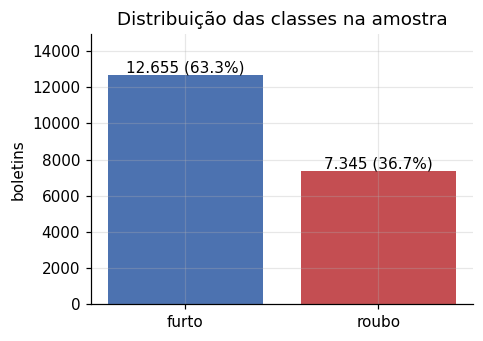

In [9]:
contagem = df["roubo"].map({0: "furto", 1: "roubo"}).value_counts()
fig, ax = plt.subplots(figsize=(4.5, 3.2))
barras = ax.bar(contagem.index, contagem.values, color=["#4C72B0", "#C44E52"])
ax.bar_label(barras, labels=[f"{v:,} ({v / len(df):.1%})".replace(",", ".") for v in contagem.values])
ax.set_ylabel("boletins")
ax.set_title("Distribuição das classes na amostra")
ax.set_ylim(0, contagem.max() * 1.18)
fig.tight_layout()
fig.savefig(FIG / "distribuicao_classes.png", dpi=200)
plt.show()

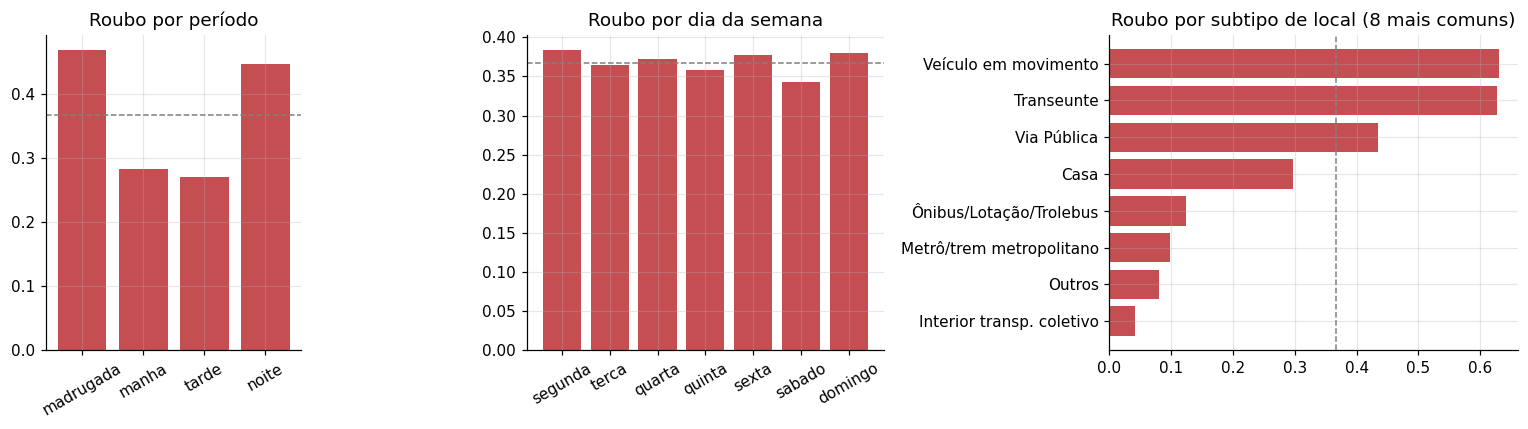

In [10]:
ordem_periodo = ["madrugada", "manha", "tarde", "noite"]
ordem_dia = ["segunda", "terca", "quarta", "quinta", "sexta", "sabado", "domingo"]
top_local = df["subtipo_local"].value_counts().head(8).index

fig, eixos = plt.subplots(1, 3, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.4, 1.6]})
for ax, col, ordem in [(eixos[0], "periodo", ordem_periodo), (eixos[1], "dia_semana", ordem_dia)]:
    taxa = df.groupby(col)["roubo"].mean().reindex(ordem)
    ax.bar(taxa.index, taxa.values, color="#C44E52")
    ax.axhline(df["roubo"].mean(), ls="--", c="gray", lw=1)
    ax.set_title({"periodo": "Roubo por período", "dia_semana": "Roubo por dia da semana"}[col])
    ax.tick_params(axis="x", rotation=30)
taxa = df[df["subtipo_local"].isin(top_local)].groupby("subtipo_local")["roubo"].mean().sort_values()
eixos[2].barh([t.replace("Metroviário e Ferroviário Metropolitano", "Metrô/trem metropolitano")
              .replace("Interior de Transporte Coletivo", "Interior transp. coletivo") for t in taxa.index],
             taxa.values, color="#C44E52")
eixos[2].axvline(df["roubo"].mean(), ls="--", c="gray", lw=1)
eixos[2].set_title("Roubo por subtipo de local (8 mais comuns)")
fig.tight_layout()
fig.savefig(FIG / "taxa_roubo_atributos.png", dpi=200)
plt.show()

Os gráficos mostram a proporção de roubo em cada categoria; a linha tracejada é a média geral (36,7%).
Madrugada e noite têm 45% a 47% de roubos, contra 27% a 28% em manhã e tarde. No metrô e no trem cerca de
90% dos casos são furto, enquanto "Veículo em movimento" e "Transeunte" passam de 60% de roubo. O dia da
semana quase não muda a proporção (de 34% a 38%); mantivemos o atributo porque a MLP pode combiná-lo com os
outros, mas é o mais fraco dos sete. Nenhum atributo separa as classes sozinho.

In [11]:
taxa_dp = df.groupby("delegacia")["roubo"].agg(boletins="count", prop_roubo="mean").sort_values("prop_roubo")
print("DPs com menor e maior proporção de roubo (mínimo de 100 BOs):")
display(pd.concat([taxa_dp[taxa_dp.boletins >= 100].head(4), taxa_dp[taxa_dp.boletins >= 100].tail(4)]).round(3))

DPs com menor e maior proporção de roubo (mínimo de 100 BOs):


,boletins,prop_roubo
delegacia,,
02º D.P. BOM RETIRO,370,0.119
78º D.P. JARDINS,595,0.155
05º D.P. ACLIMACAO,431,0.188
08º D.P. BRAS,434,0.196
89º D.P. JARDIM TABOAO,153,0.627
37º D.P. CAMPO LIMPO,406,0.665
100º D.P. JDIM HERCULANO,239,0.720
47º D.P. CAPAO REDONDO,383,0.804


### 2.4 Separação em treino, validação e teste

Divisão estratificada 70/15/15 (14.000 / 3.000 / 3.000) com semente fixa. O conjunto de **validação** é
usado para comparar arquiteturas e escolher a época de parada; o de **teste** só é usado uma vez, no final,
com o modelo já escolhido.

In [12]:
partes = dividir(df, config.ALVO, config.SEMENTE)
for nome, parte in partes.items():
    print(f"{nome:10s} {len(parte):6d} registros | proporção de roubo = {parte[config.ALVO].mean():.3f}")

treino      14000 registros | proporção de roubo = 0.367
validacao    3000 registros | proporção de roubo = 0.367
teste        3000 registros | proporção de roubo = 0.367


### 2.5 Codificação e escalonamento

As variáveis categóricas viram vetores one-hot e `qtd_celulares` é padronizada (z-score). Categorias, média
e desvio são calculados **somente no treino** e depois aplicados à validação e ao teste, para que nenhuma
informação desses conjuntos influencie o treinamento. Uma categoria que não apareceu no treino vira um vetor
de zeros. A classe `PreProcessador` (em `src/preprocessamento.py`) foi escrita à mão para poder ser salva em
JSON e reutilizada pela aplicação web.

In [13]:
prep = PreProcessador(config.CATEGORICAS, config.NUMERICAS).ajustar(partes["treino"])
X = {k: prep.transformar(v) for k, v in partes.items()}
Y = {k: v[config.ALVO].to_numpy() for k, v in partes.items()}
print("Dimensão de entrada:", X["treino"].shape[1])
print({c: len(prep.categorias[c]) for c in prep.categoricas}, "+", len(prep.numericas), "numérica")
print(f"qtd_celulares: média={prep.media['qtd_celulares']:.3f}, desvio={prep.desvio['qtd_celulares']:.3f}")

Dimensão de entrada: 166
{'delegacia': 92, 'periodo': 4, 'dia_semana': 7, 'tipo_local': 16, 'subtipo_local': 40, 'marca': 6} + 1 numérica
qtd_celulares: média=1.032, desvio=0.212


## 3. Implementação da MLP

A rede está em `src/modelo.py`:

* **Entrada:** 166 neurônios, um por coluna do vetor codificado.
* **Camadas ocultas:** densas (`nn.Linear`) seguidas de ReLU (ou tanh em um dos testes) e, opcionalmente,
  Dropout.
* **Saída:** 1 neurônio. A sigmoide desse neurônio dá P(roubo), e P(furto) = 1 − P(roubo). Para uma
  classificação binária, um neurônio de saída com sigmoide equivale a dois neurônios com softmax e tem
  menos parâmetros.
* **Perda:** entropia cruzada binária. Usamos `BCEWithLogitsLoss`, que junta sigmoide e perda numa conta só
  e é mais estável numericamente. Como a amostra tem 63% de furtos, o parâmetro `pos_weight` = nº de
  furtos / nº de roubos no treino (≈ 1,72) faz cada roubo pesar mais na perda.
* **Otimizador:** Adam, que ajusta a taxa por parâmetro e converge bem sem muito ajuste fino.
* **Treino:** mini-lotes de 256 registros, até 80 épocas, com parada antecipada: se a perda de validação não
  melhora por 15 épocas, o treino para e os pesos da melhor época são restaurados.

Em cada camada a rede calcula `a = f(W·x + b)`. O backpropagation calcula o gradiente da perda em relação a
cada `W` e `b`, e o Adam usa esses gradientes para atualizar os pesos a cada lote.

In [14]:
print(MLP(X["treino"].shape[1], [64, 32], "relu", dropout=0.3))

MLP(
  (rede): Sequential(
    (0): Linear(in_features=166, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 4. Experimentos com arquiteturas

Testamos seis configurações. Cada uma muda um fator em relação à anterior, para dar para atribuir o efeito
a uma causa:

| Modelo | Camadas ocultas | Ativação | Mudança em relação ao anterior |
|---|---|---|---|
| M1 | 16 | ReLU | linha de base: 1 camada pequena, sem peso de classe |
| M2 | 64 → 32 | ReLU | mais profundidade e neurônios |
| M3 | 64 → 32 | ReLU | + peso de classe (`pos_weight`) na perda |
| M4 | 64 → 32 | ReLU | + Dropout 0,3, weight decay 1e-3 e taxa de aprendizado 5e-4 |
| M5 | 128 → 64 → 32 | ReLU | rede maior, com Dropout 0,5 para compensar |
| M6 | 64 → 32 | tanh | troca da ativação e taxa de aprendizado 1e-2 |

In [15]:
peso_roubo = float((Y["treino"] == 0).sum() / (Y["treino"] == 1).sum())
base = dict(epocas=80, batch_size=256, paciencia=15, semente=config.SEMENTE)
EXPERIMENTOS = {
    "M1": dict(camadas=[16], ativacao="relu", lr=1e-3),
    "M2": dict(camadas=[64, 32], ativacao="relu", lr=1e-3),
    "M3": dict(camadas=[64, 32], ativacao="relu", lr=1e-3, peso_positivo=peso_roubo),
    "M4": dict(camadas=[64, 32], ativacao="relu", lr=5e-4, dropout=0.3, weight_decay=1e-3, peso_positivo=peso_roubo),
    "M5": dict(camadas=[128, 64, 32], ativacao="relu", lr=5e-4, dropout=0.5, weight_decay=1e-3, peso_positivo=peso_roubo),
    "M6": dict(camadas=[64, 32], ativacao="tanh", lr=1e-2, peso_positivo=peso_roubo),
}
print(f"pos_weight = {peso_roubo:.3f}")

resultados, modelos, historicos = [], {}, {}
for nome, cfg in EXPERIMENTOS.items():
    modelo, hist, info = treinar(X["treino"], Y["treino"], X["validacao"], Y["validacao"], **base, **cfg)
    m_tr = metricas(Y["treino"], prever_proba(modelo, X["treino"]))
    m_val = metricas(Y["validacao"], prever_proba(modelo, X["validacao"]))
    modelos[nome], historicos[nome] = modelo, hist
    resultados.append({
        "modelo": nome,
        "camadas": "-".join(map(str, cfg["camadas"])),
        "ativacao": cfg["ativacao"],
        "lr": cfg["lr"],
        "dropout": cfg.get("dropout", 0.0),
        "weight_decay": cfg.get("weight_decay", 0.0),
        "peso_classe": "sim" if cfg.get("peso_positivo") else "não",
        "parametros": info["parametros"],
        "melhor_epoca": info["melhor_epoca"],
        "epocas": info["epocas_executadas"],
        "perda_val": min(hist["perda_val"]),
        "acc_treino": m_tr["acuracia"],
        "acuracia": m_val["acuracia"],
        "precision": m_val["precision"],
        "recall": m_val["recall"],
        "f1": m_val["f1"],
    })
    print(f"{nome}: melhor época {info['melhor_epoca']:2d}/{info['epocas_executadas']:2d} | "
          f"F1 val = {m_val['f1']:.3f} | {info['tempo_s']:.1f}s")

pos_weight = 1.723


M1: melhor época 12/27 | F1 val = 0.561 | 2.8s


M2: melhor época  7/22 | F1 val = 0.561 | 2.4s


M3: melhor época  7/22 | F1 val = 0.629 | 2.8s


M4: melhor época 40/55 | F1 val = 0.637 | 9.8s


M5: melhor época 19/34 | F1 val = 0.635 | 10.9s


M6: melhor época  1/16 | F1 val = 0.625 | 2.4s


## 5. Avaliação e seleção do modelo

### 5.1 Comparação na validação

As métricas abaixo consideram roubo como classe positiva. A acurácia de referência de um classificador que
sempre responde "furto" seria 63,3%, então acurácia sozinha engana: um modelo pode ficar perto de 70% e
quase nunca acertar roubos. Por isso o critério de escolha é o **F1-score na validação**, que equilibra
precision e recall da classe roubo.

In [16]:
tabela = pd.DataFrame(resultados).set_index("modelo")
tabela.to_csv(config.PASTA_MODELO / "comparacao_arquiteturas.csv", float_format="%.4f")
cols = ["camadas", "ativacao", "lr", "dropout", "peso_classe", "parametros", "melhor_epoca",
        "acc_treino", "acuracia", "precision", "recall", "f1"]
tabela[cols].style.format({"lr": "{:.0e}", "dropout": "{:.1f}", "acc_treino": "{:.3f}", "acuracia": "{:.3f}",
                           "precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}"}).highlight_max(
    subset=["f1"], color="#d4edda")

,camadas,ativacao,lr,dropout,peso_classe,parametros,melhor_epoca,acc_treino,acuracia,precision,recall,f1
modelo,,,,,,,,,,,,
M1,16,relu,1e-03,0.0,não,2689,12,0.742,0.710,0.632,0.505,0.561
M2,64-32,relu,1e-03,0.0,não,12801,7,0.745,0.716,0.648,0.494,0.561
M3,64-32,relu,1e-03,0.0,sim,12801,7,0.736,0.709,0.591,0.672,0.629
M4,64-32,relu,5e-04,0.3,sim,12801,40,0.741,0.702,0.577,0.711,0.637
M5,128-64-32,relu,5e-04,0.5,sim,31745,19,0.742,0.704,0.580,0.701,0.635
M6,64-32,tanh,1e-02,0.0,sim,12801,1,0.722,0.701,0.579,0.679,0.625


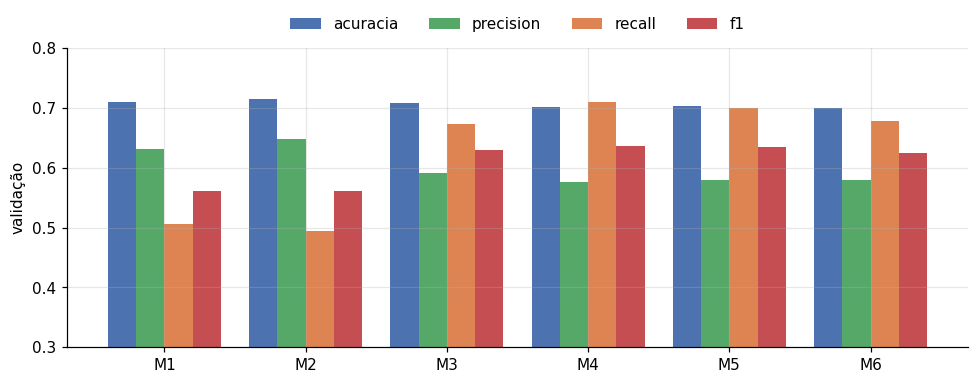

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.6))
largura = 0.2
pos = np.arange(len(tabela))
for i, (met, cor) in enumerate(zip(["acuracia", "precision", "recall", "f1"],
                                   ["#4C72B0", "#55A868", "#DD8452", "#C44E52"])):
    ax.bar(pos + (i - 1.5) * largura, tabela[met], largura, label=met, color=cor)
ax.set_xticks(pos, tabela.index)
ax.set_ylim(0.3, 0.8)
ax.set_ylabel("validação")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.15), frameon=False)
fig.tight_layout()
fig.savefig(FIG / "comparacao_arquiteturas.png", dpi=200)
plt.show()

O que os experimentos mostraram:

* **M1 → M2:** com os pesos da melhor época, as métricas praticamente não mudam (F1 0,562 e 0,560). A
  diferença está na dinâmica: o M2 atinge o mínimo da perda de validação na época 7, e daí em diante a
  validação piora enquanto o treino continua melhorando (ver curvas do M2 abaixo).
* **M2 → M3:** o peso de classe foi a mudança com maior efeito. O recall de roubo vai de 0,494 para 0,672
  e o F1 de 0,560 para 0,629, com queda de menos de 1 ponto na acurácia, já que o modelo passa a apostar
  mais em roubo.
* **M3 → M4:** Dropout, weight decay e taxa menor deixam o treino mais lento e estável. A melhor época passa
  de 7 para 40 e o recall sobe para 0,71, com o maior F1 da comparação (0,637).
* A perda de validação de M3 a M6 fica maior que a de M1 e M2 porque o `pos_weight` muda a escala da perda;
  por isso comparamos os modelos pelas métricas, e não pela perda.
* **M5:** dobrar o tamanho com Dropout forte não traz ganho; a capacidade extra não encontra mais sinal nos
  dados.
* **M6:** com tanh e lr = 1e-2 a perda de validação atinge o mínimo nas primeiras épocas e depois sobe; o
  passo grande demais faz o modelo oscilar.

In [18]:
escolhido = tabela["f1"].idxmax()
print(f"Modelo escolhido pela validação: {escolhido}")
print(tabela.loc[escolhido, ["camadas", "ativacao", "lr", "dropout", "weight_decay", "f1"]])

Modelo escolhido pela validação: M4
camadas            64-32
ativacao            relu
lr                0.0005
dropout              0.3
weight_decay       0.001
f1              0.636844
Name: M4, dtype: object


### 5.2 Curvas de treinamento e diagnóstico de overfitting

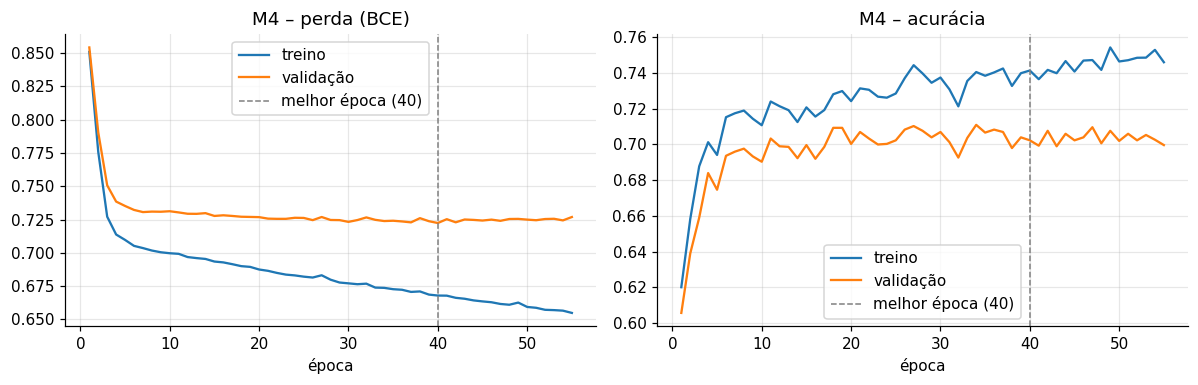

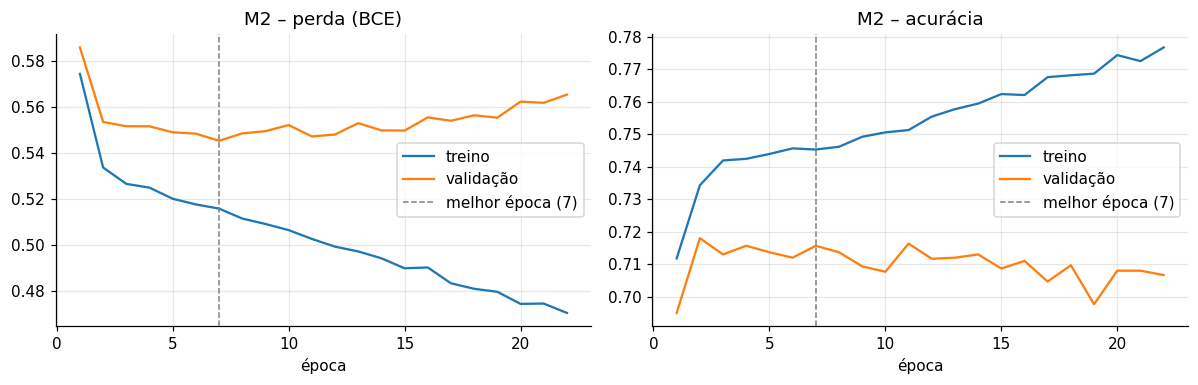

In [19]:
def plotar_curvas(nome, arquivo):
    h = historicos[nome]
    ep = np.arange(1, len(h["perda_treino"]) + 1)
    melhor = int(tabela.loc[nome, "melhor_epoca"])
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
    a1.plot(ep, h["perda_treino"], label="treino")
    a1.plot(ep, h["perda_val"], label="validação")
    a1.set_title(f"{nome} – perda (BCE)")
    a2.plot(ep, h["acc_treino"], label="treino")
    a2.plot(ep, h["acc_val"], label="validação")
    a2.set_title(f"{nome} – acurácia")
    for a in (a1, a2):
        a.axvline(melhor, ls="--", c="gray", lw=1, label=f"melhor época ({melhor})")
        a.set_xlabel("época")
        a.legend()
    fig.tight_layout()
    fig.savefig(FIG / arquivo, dpi=200)
    plt.show()


plotar_curvas(escolhido, "curvas_modelo_escolhido.png")
plotar_curvas("M2", "curvas_overfitting_M2.png")

No **M2** (sem regularização) a perda de validação atinge o mínimo na época 7 e depois sobe de 0,545 para
0,565, enquanto a de treino continua caindo e a acurácia de treino passa de 77%: é o padrão clássico de
overfitting. A rede passa a memorizar combinações raras de delegacia e local. No **M4** a perda de treino
também continua caindo, mas a de validação fica praticamente estável depois da época 10, sem a subida
observada no M2. A regularização não elimina a distância entre as curvas, mas impede que ela se transforme
em piora na validação, e a parada antecipada recupera os pesos da época 40, a de menor perda de validação.

Não há sinal de underfitting: até a rede de uma camada (M1) supera a referência de 63,3%, e redes maiores
não melhoram a validação. O teto de desempenho vem da informação disponível nos atributos, e não da
capacidade da rede.

### 5.3 Avaliação final no conjunto de teste

Teste (3000 registros) – M4
  acuracia  0.697
  precision 0.573
  recall    0.685
  f1        0.624


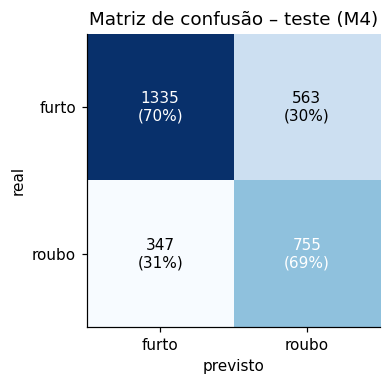

In [20]:
modelo_final = modelos[escolhido]
prob_teste = prever_proba(modelo_final, X["teste"])
m_teste = metricas(Y["teste"], prob_teste)
print(f"Teste ({len(Y['teste'])} registros) – {escolhido}")
for k in ["acuracia", "precision", "recall", "f1"]:
    print(f"  {k:9s} {m_teste[k]:.3f}")

matriz = np.array(m_teste["matriz"])
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(matriz, cmap="Blues")
ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{matriz[i, j]}\n({matriz[i, j] / matriz[i].sum():.0%})", ha="center", va="center",
                color="white" if matriz[i, j] > matriz.max() / 2 else "black")
ax.set_xticks([0, 1], ["furto", "roubo"])
ax.set_yticks([0, 1], ["furto", "roubo"])
ax.set_xlabel("previsto")
ax.set_ylabel("real")
ax.set_title(f"Matriz de confusão – teste ({escolhido})")
fig.tight_layout()
fig.savefig(FIG / "matriz_confusao.png", dpi=200)
plt.show()

A matriz de confusão mostra que o modelo acerta a maior parte dos roubos, mas classifica uma parcela
relevante de furtos como roubo. Essa troca é consequência direta do peso de classe: preferimos um modelo que
não ignore a classe minoritária, mesmo perdendo um pouco de precision. As métricas de teste ficam próximas
das de validação, o que indica que a escolha do modelo não ficou viciada no conjunto de validação.

## 6. Exportação do modelo

São salvos em `modelo/`:

* `mlp_roubo_furto.pt`: `state_dict` do PyTorch, para continuar treinando;
* `pesos_mlp.npz`: matrizes `W` e vetores `b` de cada camada, lidos pela aplicação web com NumPy;
* `preprocessador.json`: categorias, média e desvio aprendidos no treino;
* `metadados.json`: arquitetura, métricas e as opções de cada campo do formulário.

O Dropout só atua no treino; na inferência a rede é só a sequência de camadas lineares e ativações, e por
isso pode ser reproduzida em NumPy sem perda de precisão.

In [21]:
pasta = config.PASTA_MODELO
pasta.mkdir(exist_ok=True)
torch.save(modelo_final.state_dict(), pasta / "mlp_roubo_furto.pt")
exportar_pesos(modelo_final, pasta / "pesos_mlp.npz")
prep.salvar(pasta / "preprocessador.json")

treino = partes["treino"]
subtipos_por_tipo = {t: sorted(g["subtipo_local"].unique()) for t, g in treino.groupby("tipo_local")}
linha = tabela.loc[escolhido]
cfg = EXPERIMENTOS[escolhido]
metadados = {
    "modelo": escolhido,
    "arquitetura": {"entradas": int(X["treino"].shape[1]), "camadas_ocultas": cfg["camadas"],
                    "ativacao": cfg["ativacao"], "dropout": cfg.get("dropout", 0.0), "saida": "1 neurônio sigmoide"},
    "treino": {"otimizador": "Adam", "lr": cfg["lr"], "weight_decay": cfg.get("weight_decay", 0.0),
               "batch_size": base["batch_size"], "epocas_max": base["epocas"], "paciencia": base["paciencia"],
               "melhor_epoca": int(linha["melhor_epoca"]), "pos_weight": round(peso_roubo, 4)},
    "limiar": 0.5,
    "metricas_validacao": {k: round(float(linha[k]), 4) for k in ["acuracia", "precision", "recall", "f1"]},
    "metricas_teste": {k: round(float(m_teste[k]), 4) for k in ["acuracia", "precision", "recall", "f1"]},
    "matriz_teste": m_teste["matriz"],
    "opcoes": {"delegacia": prep.categorias["delegacia"], "periodo": ordem_periodo, "dia_semana": ordem_dia,
               "marca": prep.categorias["marca"], "subtipos_por_tipo": subtipos_por_tipo},
    "fonte": {"orgao": "SSP-SP", "base": "Celulares subtraídos 2025", "url": config.PAGINA_SSP,
              "registros_amostra": int(len(df))},
}
(pasta / "metadados.json").write_text(json.dumps(metadados, ensure_ascii=False, indent=2), encoding="utf-8")
print(sorted(p.name for p in pasta.iterdir()))

['comparacao_arquiteturas.csv', 'metadados.json', 'mlp_roubo_furto.pt', 'pesos_mlp.npz', 'preprocessador.json']


Conferência: a inferência em NumPy usada pela aplicação deve dar as mesmas probabilidades que o PyTorch.

In [22]:
from src.inferencia import ClassificadorOcorrencia

clf = ClassificadorOcorrencia(pasta)
p_numpy = clf.probabilidade_roubo(partes["teste"])
print("Maior diferença absoluta entre NumPy e PyTorch:", float(np.abs(p_numpy - prob_teste).max()))
exemplo = partes["teste"].iloc[0][config.CATEGORICAS + config.NUMERICAS].to_dict()
print(exemplo)
print(clf.classificar(exemplo))

Maior diferença absoluta entre NumPy e PyTorch: 1.1920928955078125e-07
{'delegacia': '23º D.P. PERDIZES', 'periodo': 'noite', 'dia_semana': 'quarta', 'tipo_local': 'Via Pública', 'subtipo_local': 'Via Pública', 'marca': 'Apple', 'qtd_celulares': 1}
{'classe': 'furto', 'prob_roubo': 0.45744308829307556, 'prob_furto': 0.5425569117069244}


## 7. Conclusões

No teste, a MLP escolhida (M4) teve acurácia de 69,7%, precision de 0,573, recall de 0,685 e F1 de 0,624
para a classe roubo. Um classificador que sempre responde "furto" teria 63,3% de acurácia e nunca
identificaria um roubo. As métricas de teste ficaram próximas das de validação. O ganho em acurácia é modesto porque os atributos permitidos (região,
período, dia, local, marca e quantidade de aparelhos) descrevem o contexto da ocorrência, e o que define
roubo é a violência ou grave ameaça, que não está nas colunas utilizáveis sem vazamento. Arquiteturas maiores
não ajudaram; o que mais mudou o resultado foi tratar o desbalanceamento das classes e regularizar a rede.

Limitações: a base não é estatística oficial (aviso da própria SSP), cobre só celulares em 2025 e a
delegacia é uma aproximação grosseira do bairro. O resultado também depende da forma como a vítima
descreve o local no BO.